In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('Salary_Data.csv')
df

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0
5,2.9,56642.0
6,3.0,60150.0
7,3.2,54445.0
8,3.2,64445.0
9,3.7,57189.0


In [22]:
df.head

<bound method NDFrame.head of     YearsExperience    Salary
0               1.1   39343.0
1               1.3   46205.0
2               1.5   37731.0
3               2.0   43525.0
4               2.2   39891.0
5               2.9   56642.0
6               3.0   60150.0
7               3.2   54445.0
8               3.2   64445.0
9               3.7   57189.0
10              3.9   63218.0
11              4.0   55794.0
12              4.0   56957.0
13              4.1   57081.0
14              4.5   61111.0
15              4.9   67938.0
16              5.1   66029.0
17              5.3   83088.0
18              5.9   81363.0
19              6.0   93940.0
20              6.8   91738.0
21              7.1   98273.0
22              7.9  101302.0
23              8.2  113812.0
24              8.7  109431.0
25              9.0  105582.0
26              9.5  116969.0
27              9.6  112635.0
28             10.3  122391.0
29             10.5  121872.0>

In [23]:
df.tail

<bound method NDFrame.tail of     YearsExperience    Salary
0               1.1   39343.0
1               1.3   46205.0
2               1.5   37731.0
3               2.0   43525.0
4               2.2   39891.0
5               2.9   56642.0
6               3.0   60150.0
7               3.2   54445.0
8               3.2   64445.0
9               3.7   57189.0
10              3.9   63218.0
11              4.0   55794.0
12              4.0   56957.0
13              4.1   57081.0
14              4.5   61111.0
15              4.9   67938.0
16              5.1   66029.0
17              5.3   83088.0
18              5.9   81363.0
19              6.0   93940.0
20              6.8   91738.0
21              7.1   98273.0
22              7.9  101302.0
23              8.2  113812.0
24              8.7  109431.0
25              9.0  105582.0
26              9.5  116969.0
27              9.6  112635.0
28             10.3  122391.0
29             10.5  121872.0>

In [24]:
df.dtypes

YearsExperience    float64
Salary             float64
dtype: object

In [25]:
x=df.iloc[:,:-1].values
y=df.iloc[:,-1].values

Text(0.5, 1.0, 'Salary_Data')

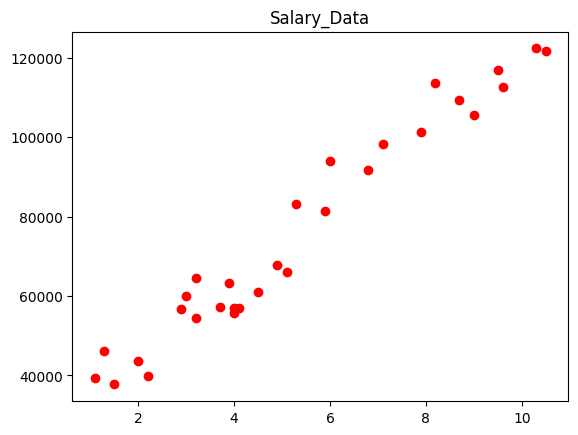

In [26]:
plt.scatter(x,y,color='r')
plt.title('Salary_Data')

In [27]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.30,random_state=1)
x_train

array([[ 7.9],
       [ 8.2],
       [ 2.2],
       [ 1.5],
       [ 9. ],
       [ 3. ],
       [ 5.9],
       [ 4.1],
       [ 3.2],
       [ 9.6],
       [ 1.3],
       [ 5.1],
       [ 1.1],
       [ 4.9],
       [10.5],
       [10.3],
       [ 3.7],
       [ 3.2],
       [ 4. ],
       [ 4. ],
       [ 2.9]])

In [28]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
y_pred

array([ 74821.41578619,  91385.43626305,  61938.28874864,  81262.97930497,
        67459.62890759,  88624.76618357, 113470.79689886,  44454.04491195,
       106109.01002026])

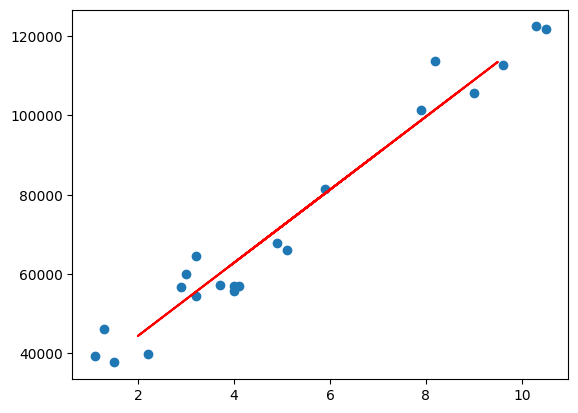

In [29]:
#regression line
plt.scatter(x_train,y_train)
plt.plot(x_test,y_pred,color='r')

In [30]:
#slope value
print(model.coef_)

[9202.23359825]


In [31]:
#constent value
print(model.intercept_)

26049.57771544336


In [32]:
#4.7 exp ,salry pred
print(model.predict([[4.7]]))

[69300.07562724]


In [33]:
df1=pd.DataFrame({'Actual_value':y_test,'Predicted_value':y_pred,'Difference':y_test-y_pred})
df1

,Actual_value,Predicted_value,Difference
0,83088.0,74821.415786,8266.584214
1,98273.0,91385.436263,6887.563737
2,63218.0,61938.288749,1279.711251
3,93940.0,81262.979305,12677.020695
4,61111.0,67459.628908,-6348.628908
5,91738.0,88624.766184,3113.233816
6,116969.0,113470.796899,3498.203101
7,43525.0,44454.044912,-929.044912
8,109431.0,106109.010020,3321.989980


In [34]:
from sklearn.metrics import mean_absolute_error
mae=mean_absolute_error(y_test,y_pred)
mae

5146.88673488824

In [35]:
from sklearn.metrics import mean_absolute_percentage_error
mape=mean_absolute_percentage_error(y_test,y_pred)
mape

0.06046677038121754

In [36]:
from sklearn.metrics import mean_squared_error
mse=mean_squared_error(y_test,y_pred)
mse

39139215.99958865

In [37]:
from sklearn.metrics import root_mean_squared_error
rmse=root_mean_squared_error(y_test,y_pred)
rmse

6256.134269625984

In [38]:
from sklearn.metrics import r2_score
score=r2_score(y_test,y_pred)
score

0.9248580247217074

In [39]:
import pickle

In [40]:
with open("model.pkl",'wb')as f:
    pickle.dump(model,f)